[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZacharyHillman18/PharmapyWorkshop/blob/main/Workshop_Challenges/solutions/Challenge3_FlowsheetDesign_solution.ipynb)

In [1]:
# Solution notebooks live in solutions/. They run from the parent folder,
# where data/ and workshop_utils.py are. (This cell is not in the student version.)
import os
import sys

if os.path.basename(os.getcwd()) == 'solutions':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

# Challenge 3: Reaction, crystallization and filtration

Each part of this notebook has a different level of guidance:

1. **Example**: fully worked. Run it and read it; it shows all the PharmaPy syntax you will need.
2. **Guided**: fill in the lines marked `# <-- COMPLETE THIS`.
3. **Unguided**: you get the task, the math and the syntax of the PharmaPy pieces; you write the code.

The plotting helpers in `workshop_utils.py` are given, so that everyone's figures look the same and results are easy to compare. The [SyntaxExamples notebook](https://colab.research.google.com/github/ZacharyHillman18/PharmapyWorkshop/blob/main/Workshop_Challenges/SyntaxExamples.ipynb) has small runnable examples of every PharmaPy object.

Rough timing: Example 10 min, Guided 15 min, Unguided 20 min, questions 5 min.

## The system

The product **C** is made in a reactor, crystallized, and filtered. In the reactor it competes with a consecutive side reaction:

$$ A + B \xrightarrow{r_1} C \qquad\qquad B + C \xrightarrow{r_2} D $$

$$ r_1 = k_1\, C_A C_B, \qquad r_2 = k_2\, C_B^2\, C_C, \qquad k_i = k_{i, ref} \exp\left[-\frac{E_i}{R}\left(\frac{1}{T} - \frac{1}{T_{ref}}\right)\right] $$

C crystallizes on cooling (same kinetics as in Challenge 2); A, B and D stay in solution. The feed contains A and B at 1.4 mol/L each. You do not need to know crystallization theory here: PharmaPy computes the crystal size distribution (CSD), and we look at a few numbers that describe it.

### Key performance indicators (KPIs)
From the contents of a crystallizer (liquid + crystals), in moles:

$$ \text{Selectivity } S = \frac{n_C}{n_C + n_D}, \qquad \text{Crystallization yield } Y = \frac{n_{C,\,crystals}}{n_{C,\,crystals} + n_{C,\,liquid}} $$

($Y$ is the fraction of the C made in the reactor that ends up as crystals), the median crystal size $d_{50}$ (by volume) and the width of the CSD, $\mathrm{span} = (d_{90} - d_{10})/d_{50}$. Larger crystals and narrower CSDs filter faster.

**Running on Google Colab?** Run the next cell first. It installs PharmaPy and puts this notebook's data files and `workshop_utils.py` on the Colab machine (about half a minute). Run it again whenever the runtime restarts. To keep your work, use *File → Save a copy in Drive*. On your own computer the cell skips the install and only unpacks the files.

In [ ]:
# @title Colab setup: run this cell first { display-mode: "form" }
# Installs PharmaPy and unpacks workshop_utils.py and data/ into the working
# directory. Run it again after a runtime restart or a factory reset.
import base64, importlib.metadata, importlib.util, io, os, subprocess, sys, zipfile

if 'google.colab' in sys.modules or importlib.util.find_spec('PharmaPy') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pharmapy-org>=0.3.1'], check=True)

_FILES = (
    '...'
)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_FILES))) as archive:
    archive.extractall('.')
importlib.invalidate_caches()

try:
    _version = importlib.metadata.version('pharmapy-org')
except importlib.metadata.PackageNotFoundError:   # a development install of PharmaPy
    _version = '(development install)'
print('PharmaPy', _version, '- workshop files ready in', os.getcwd())

## Setup (given)

Kinetics, base operating conditions, the filter size, and three small functions that create the **phases** used by every unit. Each call returns a new object: units, phases, kinetics and integrators cannot be shared between units or reused between simulations.

All simulations are for **1 L** of reactor product. The filtration time depends only on the slurry volume per filter area, so filtering 1 L on a 1.5 cm lab filter takes exactly as long as filtering a 100 L batch on a 15 cm plant filter.

In [2]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar, brentq

from PharmaPy.Phases_Refactored import LiquidPhase, SolidPhase
from PharmaPy.Streams_Refactored import LiquidStream
from PharmaPy.Reactors_Refactored import BatchReactor, ContinuousReactor
from PharmaPy.Crystallizers_Refactored import BatchCrystallizer, SemiBatchCrystallizer, ContinuousCrystallizer
from PharmaPy.SolidLiquidSep_Refactored import Filter
from PharmaPy.Mechanisms import OneDFVMMechanism
from PharmaPy.Kinetics import RxnKinetics, CrystKinetics
from PharmaPy.ProcessControl_Refactored import SimpleTemperatureController, ContinuousVesselController
from PharmaPy.IntegratorBackends import ScipyBackend
from PharmaPy.SimExec import SimulationExec

from workshop_utils import (apply_pharmapy_patches, csd_quantiles, plot_concentrations, plot_csds,
                            plot_kpi_bars)

apply_pharmapy_patches()

path = 'data/compounds_workshop.json'   # species: A, B, C, D, solvent
with open(path) as f:
    database = json.load(f)
SPECIES = list(database)
MW = np.array([database[name]['mw'] for name in SPECIES], dtype=float)   # g/mol = kg/kmol
RHO_SOLVENT = database['solvent']['rho_liq']                            # kg/m3


def rxn_kinetics():
    return RxnKinetics(path, rxn_list=['A + B --> C', 'B + C --> D'],
                       k_params=[5e-3, 2e-3],          # at T_ref: L/(mol s) and L^2/(mol^2 s)
                       ea_params=[40e3, 70e3],         # J/mol
                       temp_ref=333.15,
                       params_f=[[1, 1], [2, 1]])      # orders: r1 = k1 CA CB, r2 = k2 CB^2 CC


def cryst_kinetics():
    return CrystKinetics(np.array([-28.13909202, 0.001, 5.900800253]),
                         nucl_prim=(1.0448e17, 0, 8.30671806), growth=(2.4297e4, 0, 4.52241037),
                         solubility_type='apelblat', solubility_basis='mass_per_volume_solvent')


OPS = {'C0': 1.4,        # mol/L of A and of B in the feed
       'T_R': 333.15,    # reactor temperature (K)
       't_R': 3600.,     # reaction time, or residence time of the CSTR (s)
       'V_R': 1e-3,      # reactor volume (m3)
       'T_C': 273.15,    # final / MSMPR crystallizer temperature (K)
       't_C': 3600.}     # cooling time, or MSMPR residence time (s)
T_HOLD = 1800.                       # s, final hold of a batch crystallizer
X_GRID = np.geomspace(1, 1500, 30)   # um, size grid of the population balances
FILTER_DIAM = 0.015                  # m, lab filter (1 L on 1.5 cm = 100 L on 15 cm)
DELTA_P = 1e5                        # Pa, filtration pressure drop


def integrator(maxh=600):
    """A new solver for each unit; stall_calls makes it give up quickly if it gets stuck."""
    return ScipyBackend(options={'maxh': maxh}, stall_calls=20000)


def solvent_liquid(T, vol, mole_conc=(0, 0, 0, 0, 0)):
    """Liquid of volume vol (m3) at T (K) with concentrations mole_conc (mol/L of A, B, C, D, solvent)."""
    return LiquidPhase(path, temp=T, vol=vol, mole_conc=list(mole_conc), name_solv='solvent')


def saturated_liquid(T, vol):
    """Solution of C saturated at T, e.g. to start up a continuous crystallizer."""
    c_sat = cryst_kinetics().get_solubility(T)    # kg C / m3 solvent
    w_sat = c_sat / (c_sat + RHO_SOLVENT)
    return LiquidPhase(path, temp=T, vol=vol, mass_frac=[0, 0, w_sat, 0, 1 - w_sat], name_solv='solvent')


def fvm_solid(T, distrib=None):
    """Solid phase of C with its population balance (1D-FVM on X_GRID) attached; no crystals by default."""
    solid = SolidPhase(path, temp=T, mass=0, mass_frac=[0, 0, 1, 0, 0])
    solid.mechanisms = OneDFVMMechanism(solid, target_components='C', solvent_name='solvent', x_grid=X_GRID,
                                        distrib_init=np.zeros_like(X_GRID) if distrib is None else distrib)
    return solid

Your PharmaPy version needs no workshop fixes.


---
# Part 1 — Example: batch reactor → batch crystallizer → filter

Units are connected with `SimulationExec` and a **flowsheet string** (`'R01 --> CR01 --> F01'`); each unit is then assigned as an attribute with that name. When a batch unit finishes, PharmaPy charges its contents to the next one, replacing that unit's placeholder phases. Each unit gets its own solver settings through `kwargs_run`.

* `R01`: batch reactor at constant `T_R` for `t_R`;
* `CR01`: batch crystallizer, cooling linearly from `T_R` to `T_C` in `t_C`, then holding for `T_HOLD`;
* `F01`: a **filter**, which is also a batch unit: it receives the whole slurry of `CR01`.

### The filter
PharmaPy's `Filter` models dead-end cake filtration at a constant pressure drop. The filtrate volume $V$ follows Darcy's law through the growing cake and the filter medium:

$$ \frac{dV}{dt} = \frac{\Delta P\, A}{\mu \left( \alpha\, c\, V / A + R_m \right)}, \qquad \alpha = \sum_i w_i\, \frac{180\,(1-\varepsilon)}{\varepsilon^3\, \rho_s\, x_i^2} $$

* `station_diam` (m) sets the filter area $A$; `deltaP` (Pa) the pressure drop; `resist_medium` the medium resistance $R_m$ (default 1e9 1/m).
* `alpha`, the specific cake resistance (m/kg), is **computed from the CSD** when you do not give it (Kozeny-Carman: $w_i$ is the volume fraction of crystals of size $x_i$), and the cake porosity $\varepsilon$ from the width of the CSD. Small crystals (the $1/x_i^2$) and broad CSDs filter slowly.
* The run stops by itself when no more filtrate comes out (a terminal event), so `runtime` only needs to be long enough; the last time is the **filtration time**.
* Like the crystallizer, it needs placeholder phases with the same size grid: a liquid and a solid with its population balance.

In [3]:
cooling = lambda t: np.interp(t, [0, OPS['t_C']], [OPS['T_R'], OPS['T_C']])   # K; holds T_C after t_C

flst = SimulationExec(path, flowsheet='R01 --> CR01 --> F01')

flst.R01 = BatchReactor(integrator=integrator(),
                        controller=SimpleTemperatureController(temp_func=lambda t: OPS['T_R']))
flst.R01.Phases = solvent_liquid(OPS['T_R'], OPS['V_R'], (OPS['C0'], OPS['C0'], 0, 0, 0))
flst.R01.RxnKinetics = rxn_kinetics()

flst.CR01 = BatchCrystallizer(integrator=integrator(60),
                              controller=SimpleTemperatureController(temp_func=cooling))
flst.CR01.Phases = [solvent_liquid(OPS['T_R'], OPS['V_R']), fvm_solid(OPS['T_R'])]   # placeholder liquid
flst.CR01.CrystKinetics = cryst_kinetics()

flst.F01 = Filter(station_diam=FILTER_DIAM,       # m: filter diameter
                  deltaP=DELTA_P,                 # Pa: pressure drop across cake + medium
                  integrator=ScipyBackend())      # alpha is not given: computed from the CSD
flst.F01.Phases = [solvent_liquid(OPS['T_C'], OPS['V_R']), fvm_solid(OPS['T_C'])]       # placeholders

tic = time.perf_counter()
flst.SolveFlowsheet(kwargs_run={'R01': {'time_grid': np.linspace(0, OPS['t_R'], 31), 'verbose': False},
                                'CR01': {'time_grid': np.linspace(0, OPS['t_C'] + T_HOLD, 41), 'verbose': False},
                                'F01': {'runtime': 1e5, 'verbose': False}},   # stops itself when done
                    verbose=False)
print('simulation time: %.1f s' % (time.perf_counter() - tic))

simulation time: 1.5 s


### Reading the results

* `unit.result.mass_j_liquid0[-1]`: kg of each species (A, B, C, D, solvent) in the liquid at the end; divide by `MW` for kmol;
* `unit.Phases.Solids[0].mass`: kg of crystals in the unit at the end;
* `unit.Phases.Solids[0].mechanisms[0]`: the population balance of the crystals, with its grid `x_grid` and cell widths `dx`; `unit.result.distrib_solid0[-1]` is the final number density, which `csd_quantiles` turns into $d_{10}$, $d_{50}$, $d_{90}$ and the span;
* the filter: `F01.result.time[-1]` is the filtration time and `F01.alpha` the cake resistance it computed. `F01.Outlet['cake']` is the cake (`.Solids[0].mass`: the crystals; `.Liquids[0].mass`: the liquid left in its pores) and `F01.Outlet['filtrate']` the filtrate stream. `F01.result.mass_j_liquid0` is the liquid still in the filter, so the filtrate collected is the initial liquid minus that.

{'selectivity': np.float64(0.853), 'yield': np.float64(0.531), 'd50': np.float64(119.781), 'span': np.float64(0.62), 't_filt (min)': np.float64(19.063)}
cake: 0.1145 kg of crystals and 0.0452 kg of liquid in its pores; filtrate: 0.750 kg; alpha = 1.17e+08 m/kg


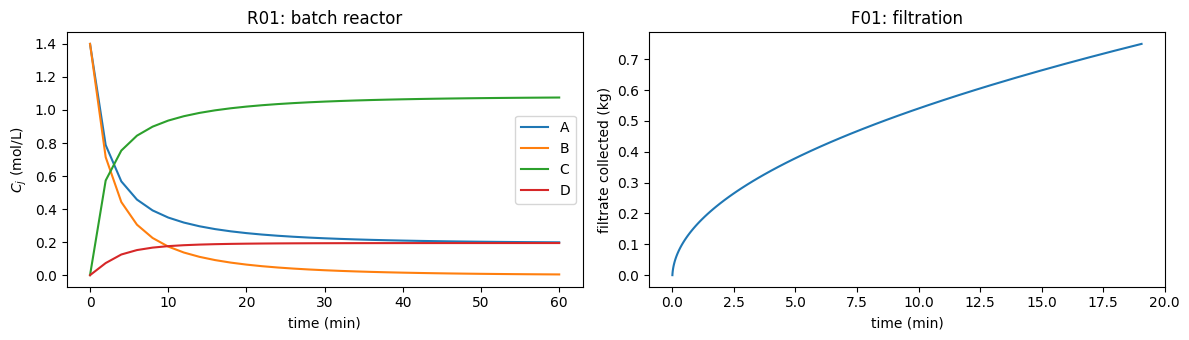

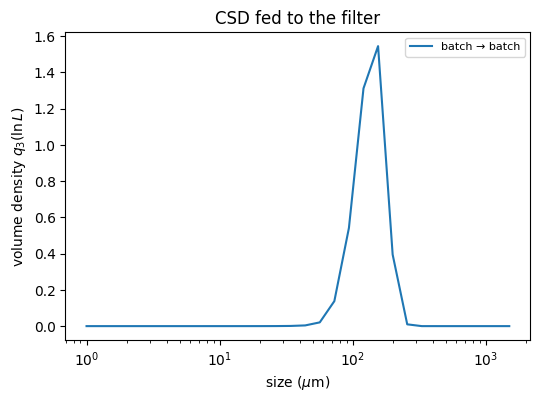

In [4]:
cr = flst.CR01
n_liq = cr.result.mass_j_liquid0[-1] / MW     # kmol of A, B, C, D, solvent in the mother liquor
n_cryst = cr.Phases.Solids[0].mass / MW[2]    # kmol of C in the crystals
n_C = n_liq[2] + n_cryst

mech = cr.Phases.Solids[0].mechanisms[0]
csd = csd_quantiles(mech.x_grid, cr.result.distrib_solid0[-1], mech.dx)

filt = flst.F01
t_filt = filt.result.time[-1]
kpis_batch = {'selectivity': n_C / (n_C + n_liq[3]), 'yield': n_cryst / n_C,
              'd50': csd['d50'], 'span': csd['span'], 't_filt (min)': t_filt / 60}
print({key: round(val, 3) for key, val in kpis_batch.items()})
liquid_held = filt.result.mass_j_liquid0.sum(axis=1)                   # kg of liquid still in the filter
cake = filt.Outlet['cake']
print('cake: %.4f kg of crystals and %.4f kg of liquid in its pores; filtrate: %.3f kg; alpha = %.2e m/kg'
      % (cake.Solids[0].mass, cake.Liquids[0].mass, liquid_held[0] - liquid_held[-1], filt.alpha))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_concentrations(flst.R01.result.time, flst.R01.result.mole_conc_liquid0, ax=axes[0], time_unit='min',
                    title='R01: batch reactor')
axes[1].plot(filt.result.time / 60, liquid_held[0] - liquid_held)
axes[1].set_xlabel('time (min)')
axes[1].set_ylabel('filtrate collected (kg)')
axes[1].set_title('F01: filtration')
fig.tight_layout()
plt.show()
plot_csds({'batch → batch': flst.CR01}, title='CSD fed to the filter')

---
# Part 2 — Guided: a continuous flowsheet (CSTR → MSMPR → holding tank → filter)

A continuous unit needs a controller that keeps its volume constant (the outlet follows the inlet): `ContinuousVesselController(temp_func=...)`, which also sets its temperature. Only the **first** unit of a flowsheet gets an `Inlet`; `SimulationExec` passes the outlet of each unit to the next one. The units start up full of solvent (CSTR) or of saturated solution (MSMPR, to avoid a nucleation burst at $t = 0$) and run for 6 total residence times to reach steady state.

**A filter cannot take a continuous stream.** It is a batch unit, and connecting the MSMPR straight to it fails with

> `TypeError: Filter is a batch unit and cannot be fed directly from a continuous one: a flow has to be accumulated into a charge first. Put a holding vessel (...) between them.`

So the slurry is first collected in a **holding tank**: a semibatch vessel (here a `SemiBatchCrystallizer` kept at `T_C`, starting with a small heel of saturated solution) that receives the whole outlet of the MSMPR. Its contents are then filtered. The tank collects about 12 L over the run, so the lab filter takes it in 12 loads of 1 L: `Filter(..., slurry_div=12)` splits the charge into 12 filtration cycles and reports the time of one, which is comparable with Part 1.

First write the unit factories and a KPI function for any crystallizer (repeat Part 1 for a given unit).

In [5]:
def make_cstr(T, vol, feed=None):
    cstr = ContinuousReactor(integrator=integrator(), controller=ContinuousVesselController(temp_func=lambda t: T))  # [blank] ContinuousReactor with its own integrator() and a ContinuousVesselController at T
    cstr.Phases = solvent_liquid(T, vol)  # [blank] start-up: full of solvent (volume vol at T)
    cstr.RxnKinetics = rxn_kinetics()  # [blank] attach a new reaction kinetics object
    if feed is not None:
        cstr.Inlet = feed  # [blank] connect the feed stream
    return cstr


def make_msmpr(T, vol):
    msmpr = ContinuousCrystallizer(integrator=integrator(), controller=ContinuousVesselController(temp_func=lambda t: T))  # [blank] ContinuousCrystallizer with its own integrator() and a ContinuousVesselController at T
    msmpr.Phases = [saturated_liquid(T, vol), fvm_solid(T)]  # [blank] start-up: saturated solution and a solid without crystals
    msmpr.CrystKinetics = cryst_kinetics()  # [blank] attach a new crystallization kinetics object
    return msmpr


def make_holding_tank(T, vol_heel):
    tank = SemiBatchCrystallizer(integrator=integrator(), controller=SimpleTemperatureController(temp_func=lambda t: T))  # [blank] SemiBatchCrystallizer with its own integrator() and a SimpleTemperatureController at T
    tank.Phases = [saturated_liquid(T, vol_heel), fvm_solid(T)]  # [blank] a small heel of saturated solution and a solid without crystals
    tank.CrystKinetics = cryst_kinetics()  # [blank] attach a new crystallization kinetics object
    return tank


def crystal_kpis(unit):
    """Selectivity, crystallization yield, d50 and span from the final contents of a crystallizer."""
    n_liq = unit.result.mass_j_liquid0[-1] / MW  # [blank] kmol of each species in the liquid at the end
    n_cryst = unit.Phases.Solids[0].mass / MW[2]  # [blank] kmol of C in the crystals
    n_C = n_liq[2] + n_cryst
    mech = unit.Phases.Solids[0].mechanisms[0]  # [blank] the population balance of the crystals
    csd = csd_quantiles(mech.x_grid, unit.result.distrib_solid0[-1], mech.dx)  # [blank] CSD statistics of the final distribution
    return {'selectivity': n_C / (n_C + n_liq[3]), 'yield': n_cryst / n_C, 'd50': csd['d50'], 'span': csd['span']}


print(crystal_kpis(flst.CR01))    # should match Part 1

{'selectivity': np.float64(0.853320726508775), 'yield': np.float64(0.5308258175118247), 'd50': np.float64(119.78071826518467), 'span': np.float64(0.6195570060668899)}


Now build and solve the continuous flowsheet `'R01 --> CR01 --> HOLD01 --> F01'`: a CSTR with residence time `t_R` (volume `V_R`), an MSMPR at `T_C` with residence time `t_C`, the holding tank at `T_C` (heel: 2 % of `V_R`), and the filter. The feed flow is `V_R / t_R`.

simulation time: 9.1 s
                          selectivity  yield      d50   span  t_filt (min)
batch → batch (Part 1)          0.853  0.531  119.781  0.620        19.063
MSMPR at steady state           0.827  0.396  373.288  1.317           NaN
holding tank (collected)        0.846  0.332  333.163  1.470         4.001


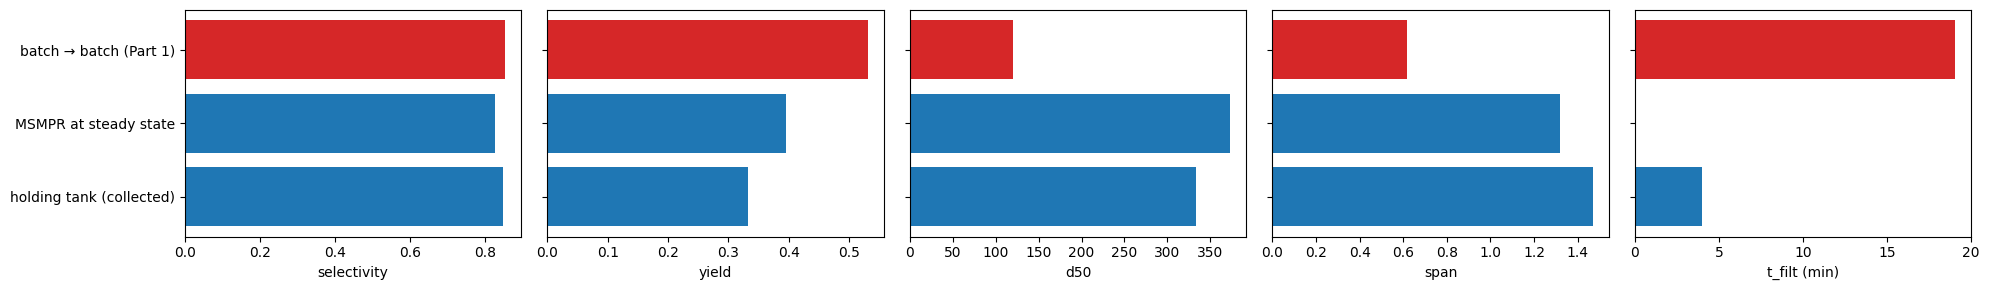

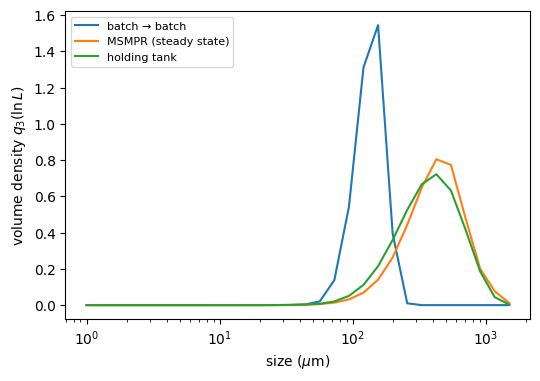

In [6]:
vol_flow = OPS['V_R'] / OPS['t_R']     # m3/s
horizon = 6 * (OPS['t_R'] + OPS['t_C'])
n_loads = round(vol_flow * horizon / OPS['V_R'])     # 1 L loads the tank collects (about 12)
feed = LiquidStream(path, temp=OPS['T_R'], vol_flow=vol_flow, mole_conc=[OPS['C0'], OPS['C0'], 0, 0, 0], name_solv='solvent')  # [blank] feed: LiquidStream at T_R with vol_flow and A and B at C0 each (mole_conc, name_solv='solvent')

flst_cont = SimulationExec(path, flowsheet='R01 --> CR01 --> HOLD01 --> F01')  # [blank] SimulationExec for R01 --> CR01 --> HOLD01 --> F01
flst_cont.R01 = make_cstr(OPS['T_R'], OPS['V_R'], feed)  # [blank] the CSTR (with the feed)
flst_cont.CR01 = make_msmpr(OPS['T_C'], vol_flow * OPS['t_C'])  # [blank] the MSMPR (residence time t_C)
flst_cont.HOLD01 = make_holding_tank(OPS['T_C'], 0.02 * OPS['V_R'])  # [blank] the holding tank at T_C
flst_cont.F01 = Filter(station_diam=FILTER_DIAM, deltaP=DELTA_P, slurry_div=n_loads, integrator=ScipyBackend())  # [blank] the filter, as in Part 1, taking the tank in n_loads loads (slurry_div=n_loads)
flst_cont.F01.Phases = [solvent_liquid(OPS['T_C'], OPS['V_R']), fvm_solid(OPS['T_C'])]   # placeholders

time_grid = np.linspace(0, horizon, 41)
tic = time.perf_counter()
# [blank-start] solve the flowsheet: time_grid for R01, CR01 and HOLD01, runtime=1e5 for F01 (verbose=False everywhere)
flst_cont.SolveFlowsheet(kwargs_run={'R01': {'time_grid': time_grid, 'verbose': False},
                                     'CR01': {'time_grid': time_grid, 'verbose': False},
                                     'HOLD01': {'time_grid': time_grid, 'verbose': False},
                                     'F01': {'runtime': 1e5, 'verbose': False}}, verbose=False)
# [blank-end]
print('simulation time: %.1f s' % (time.perf_counter() - tic))

kpi_table = pd.DataFrame({'batch → batch (Part 1)': kpis_batch,
                          'MSMPR at steady state': crystal_kpis(flst_cont.CR01),
                          'holding tank (collected)': {**crystal_kpis(flst_cont.HOLD01),
                                                       't_filt (min)': flst_cont.F01.result.time[-1] / 60}}).T
print(kpi_table.round(3))
plot_kpi_bars(kpi_table)
plot_csds({'batch → batch': flst.CR01, 'MSMPR (steady state)': flst_cont.CR01, 'holding tank': flst_cont.HOLD01})

---
# Part 3 — Unguided: the fastest batch, and batch vs continuous

Each batch of reactor product must be crystallized and filtered as quickly as possible, and the crystals must meet the size specification $d_{50} \ge 90\ \mu m$. Minimize the **total time per batch**

$$ \min \; t_{total} = t_{cryst} + t_{filt} \qquad \text{subject to} \qquad d_{50} \ge 90\ \mu m $$

over these crystallization options:

* **batch** crystallizer, charged with 1 L of reactor product: cooling from $T_R$ to `T_C` with $T(t) = T_C + (T_R - T_C)\,[1 - (t/t_{cool})^p]$, then a hold of `T_HOLD`, so $t_{cryst} = t_{cool} + T_{HOLD}$. Decision variables: $5 \le t_{cool} \le 180$ min and $0.5 \le p \le 3$.
* a train of **1, 2 or 3 MSMPRs** in series, with total volume 1 L and total residence time $\tau$ (split equally; stage temperatures evenly spaced from 293 K to `T_C`). It processes one batch volume every $\tau$, so $t_{cryst} = \tau$, with $10 \le \tau \le 240$ min. Its product goes through a holding tank (Part 2) to the filter; here we filter a 1 L sample of the **steady-state** product (`product_sample`, given below), i.e. the start-up material is diverted.

$t_{filt}$ is the time to filter 1 L of the product slurry on the lab filter of Part 1.

**Tasks**
* **(a)** Write `run_batch_cryst(feed, t_cool, p)`, `run_msmpr_train(feed, n, tau)` and `evaluate(unit, t_cryst)`, which returns $t_{total}$, $t_{filt}$, $d_{50}$, span and $Y$.
* **(b)** Optimize the batch crystallizer for the **batch-reactor product** (Nelder-Mead, about 20 evaluations; handle the bounds and the $d_{50}$ constraint with penalties). Which constraint is active?
* **(c)** Find the best MSMPR train: minimize over $\tau$ for $n = 1$ (bounded 1-D search), and evaluate $n$ = 2 and 3 at $\tau$ = 10 and 30 min. Is the best train faster than the best batch?
* **(d)** Does the reaction step matter? With the **CSTR product** of Part 2, repeat (b) and evaluate the trains of (c): one MSMPR at its best $\tau$, and 2 and 3 MSMPRs at $\tau$ = 10 and 30 min. Compare yield, $d_{50}$ and $t_{total}$ with the batch-reactor product.
* **(e)** The product is valuable: add the specification $Y \ge 0.50$. Which designs are still feasible, and which route wins now? (For one MSMPR, find the shortest $\tau$ that meets it.)

**Syntax you need**
```python
# filtering 1 L of the final contents of a crystallizer (product_sample is given below)
filt = Filter(station_diam=FILTER_DIAM, deltaP=DELTA_P, integrator=ScipyBackend())
filt.Phases = product_sample(unit)                      # [liquid, solid] of 1 L of product slurry
filt.solve_unit(runtime=1e5, verbose=False)
t_filt = filt.result.time[-1]                           # s

# a train of MSMPRs: name the units, then build them in a loop
names = ['CR%02d' % (i + 1) for i in range(n)]          # 'CR01', 'CR02', ...
train = SimulationExec(path, flowsheet=' --> '.join(names))
setattr(train, name, make_msmpr(T_stage, OPS['V_R'] / n))         # your factory from Part 2
train.CR01.Inlet = LiquidStream(path, temp=OPS['T_R'], vol_flow=OPS['V_R'] / tau, mole_conc=list(feed),
                                name_solv='solvent')
train.SolveFlowsheet(kwargs_run={name: {'time_grid': np.linspace(0, 6 * tau, 31), 'verbose': False}
                                 for name in names}, verbose=False)
getattr(train, names[-1])                               # the last crystallizer

minimize(f, x0, method='Nelder-Mead', options={'maxfev': 20, 'initial_simplex': [...]})
minimize_scalar(f, bounds=(lo, hi), method='bounded', options={'xatol': ...})
brentq(g, lo, hi, xtol=...)                             # root of g between lo and hi
```
The batch crystallizer is built as in Part 1, with the reactor product as its charge: `solvent_liquid(OPS['T_R'], OPS['V_R'], feed)`. Use `crystal_kpis` (Part 2) for $d_{50}$, span and $Y$. A batch simulation takes about 1 s, an MSMPR train 5-20 s. Plotting helpers: `plot_kpi_bars(dataframe)`, `plot_csds({label: unit, ...})`.

In [7]:
FEED_BATCH = flst.R01.result.mole_conc_liquid0[-1]        # mol/L: product of the batch reactor (Part 1)
FEED_CSTR = flst_cont.R01.result.mole_conc_liquid0[-1]    # mol/L: steady-state product of the CSTR (Part 2)
D50_MIN = 90.0                                            # um
Y_MIN = 0.50                                              # for task (e)
print(pd.DataFrame({'batch reactor': FEED_BATCH, 'CSTR': FEED_CSTR}, index=SPECIES).T.round(3))


def product_sample(unit, vol_slurry=OPS['V_R']):
    # liquid and solid phases of vol_slurry m3 of the final contents of a crystallizer, ready for a Filter
    mech = unit.Phases.Solids[0].mechanisms[0]
    distrib = np.asarray(unit.result.distrib_solid0[-1])           # #/(um m3 of slurry)
    phi = np.sum(distrib * mech.x_grid**3 * mech.dx) * 1e-18       # volume fraction of crystals
    mass_j = np.asarray(unit.result.mass_j_liquid0[-1])
    T = unit.result.global_temp[-1]
    liquid = LiquidPhase(path, temp=T, vol=vol_slurry * (1 - phi), mass_frac=list(mass_j / mass_j.sum()))
    return [liquid, fvm_solid(T, distrib)]

                   A      B      C      D  solvent
batch reactor  0.199  0.004  1.075  0.194    9.001
CSTR           0.355  0.166  0.916  0.189    8.951


In [8]:
# [blank-start] your code: (a) the two crystallization options and their evaluation
T_R, T_C = OPS['T_R'], OPS['T_C']


def run_batch_cryst(feed, t_cool, p):
    cooling = lambda t: T_C + (T_R - T_C) * (1 - min(t / t_cool, 1.0)**p)
    cryst = BatchCrystallizer(integrator=integrator(60),
                              controller=SimpleTemperatureController(temp_func=cooling))
    cryst.Phases = [solvent_liquid(T_R, OPS['V_R'], feed), fvm_solid(T_R)]
    cryst.CrystKinetics = cryst_kinetics()
    cryst.solve_unit(time_grid=np.linspace(0, t_cool + T_HOLD, 41), verbose=False)
    return cryst


def run_msmpr_train(feed, n, tau, n_tau=6):
    names = ['CR%02d' % (i + 1) for i in range(n)]
    temps = [T_C] if n == 1 else np.linspace(293.15, T_C, n)
    train = SimulationExec(path, flowsheet=' --> '.join(names))
    for name, T in zip(names, temps):
        setattr(train, name, make_msmpr(T, OPS['V_R'] / n))
    train.CR01.Inlet = LiquidStream(path, temp=T_R, vol_flow=OPS['V_R'] / tau, mole_conc=list(feed),
                                    name_solv='solvent')
    time_grid = np.linspace(0, n_tau * tau, 31)
    train.SolveFlowsheet(kwargs_run={name: {'time_grid': time_grid, 'verbose': False} for name in names},
                         verbose=False)
    return getattr(train, names[-1])


def filtration_time(unit):
    filt = Filter(station_diam=FILTER_DIAM, deltaP=DELTA_P, integrator=ScipyBackend())
    filt.Phases = product_sample(unit)
    filt.solve_unit(runtime=1e5, verbose=False)
    return filt.result.time[-1]


def evaluate(unit, t_cryst):
    kpis = crystal_kpis(unit)
    t_filt = filtration_time(unit)
    return {'t_total (min)': (t_cryst + t_filt) / 60, 't_cryst (min)': t_cryst / 60, 't_filt (min)': t_filt / 60,
            'd50': kpis['d50'], 'span': kpis['span'], 'Y': kpis['yield']}


print({key: round(val, 3) for key, val in evaluate(run_batch_cryst(FEED_BATCH, 3600, 1.0), 3600 + T_HOLD).items()})
# [blank-end]

{'t_total (min)': np.float64(111.23), 't_cryst (min)': 90.0, 't_filt (min)': np.float64(21.23), 'd50': np.float64(119.781), 'span': np.float64(0.62), 'Y': np.float64(0.531)}


optimization time: 27 s
t_cool (min)     15.422
p                 0.539
t_total (min)    77.397
t_cryst (min)    45.422
t_filt (min)     31.975
d50              97.549
span              0.683
Y                 0.531
Name: 16, dtype: float64


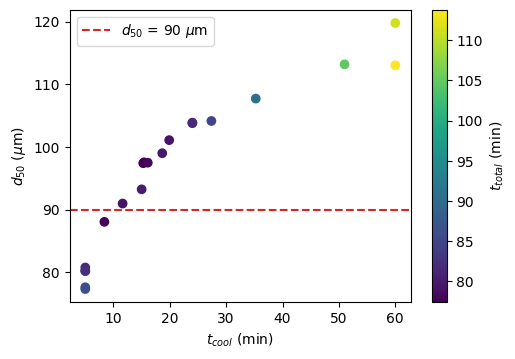

In [9]:
# [blank-start] your code: (b) the fastest batch with d50 >= 90 um (batch-reactor product)
LOWER, UPPER = np.array([300., 0.5]), np.array([10800., 3.0])     # t_cool (s), p


def optimize_batch(feed, x0=(3600., 1.0), maxfev=20):
    history = []

    def objective(x):
        x_clip = np.clip(x, LOWER, UPPER)
        bounds_penalty = 1e4 * np.sum(((x - x_clip) / (UPPER - LOWER))**2)
        res = evaluate(run_batch_cryst(feed, *x_clip), x_clip[0] + T_HOLD)
        history.append({'t_cool (min)': x_clip[0] / 60, 'p': x_clip[1], **res})
        d50_penalty = 1e4 * max(0.0, (D50_MIN - res['d50']) / D50_MIN)**2
        return res['t_total (min)'] + d50_penalty + bounds_penalty

    x0 = np.array(x0)
    minimize(objective, x0, method='Nelder-Mead',
             options={'maxfev': maxfev, 'initial_simplex': [x0, x0 * [0.4, 1], x0 + [0, 1.0]]})
    history = pd.DataFrame(history)
    feasible = history[history['d50'] >= D50_MIN]
    return feasible.loc[feasible['t_total (min)'].idxmin()], history


tic = time.perf_counter()
best_batch, history_batch = optimize_batch(FEED_BATCH)
print('optimization time: %.0f s' % (time.perf_counter() - tic))
print(best_batch.round(3))

fig, ax = plt.subplots(figsize=(5.5, 3.8))
sc = ax.scatter(history_batch['t_cool (min)'], history_batch['d50'], c=history_batch['t_total (min)'], cmap='viridis')
ax.axhline(D50_MIN, color='C3', ls='--', label='$d_{50}$ = 90 $\\mu$m')
fig.colorbar(sc, label='$t_{total}$ (min)')
ax.set_xlabel('$t_{cool}$ (min)')
ax.set_ylabel(r'$d_{50}$ ($\mu$m)')
ax.legend()
plt.show()
# [blank-end]

In [10]:
# [blank-start] your code: (c) the best MSMPR train (batch-reactor product)
def t_total_msmpr(tau, feed=FEED_BATCH, n=1):
    res = evaluate(run_msmpr_train(feed, n, tau), tau)
    return res['t_total (min)'] + 1e4 * max(0.0, (D50_MIN - res['d50']) / D50_MIN)**2


tic = time.perf_counter()
best_tau = minimize_scalar(t_total_msmpr, bounds=(600, 14400), method='bounded', options={'xatol': 60})
rows = [{'MSMPRs': 1, 'tau (min)': best_tau.x / 60, **evaluate(run_msmpr_train(FEED_BATCH, 1, best_tau.x), best_tau.x)}]
for n in [2, 3]:
    for tau in [600., 1800.]:
        rows.append({'MSMPRs': n, 'tau (min)': tau / 60, **evaluate(run_msmpr_train(FEED_BATCH, n, tau), tau)})
trains = pd.DataFrame(rows)
print('time: %.0f s' % (time.perf_counter() - tic))
print(trains.round(3).to_string())
# [blank-end]

time: 124 s
   MSMPRs  tau (min)  t_total (min)  t_cryst (min)  t_filt (min)      d50   span      Y
0       1     10.381         18.760         10.381         8.379  357.656  1.297  0.487
1       2     10.000         21.479         10.000        11.479  228.829  1.244  0.472
2       2     30.000         38.195         30.000         8.195  278.104  1.264  0.478
3       3     10.000         23.370         10.000        13.370  207.268  1.262  0.475
4       3     30.000         39.195         30.000         9.195  251.639  1.242  0.481


time: 105 s
MSMPR trains, CSTR product:
   MSMPRs  tau (min)  t_total (min)  t_cryst (min)  t_filt (min)      d50   span      Y
0       1     10.381         17.464         10.381         7.083  334.062  1.228  0.401
1       2     10.000         20.035         10.000        10.035  209.944  1.224  0.384
2       2     30.000         36.971         30.000         6.971  253.736  1.176  0.392
3       3     10.000         21.393         10.000        11.393  185.068  1.167  0.389
4       3     30.000         38.106         30.000         8.106  225.725  1.185  0.396
                                   t_total (min)  t_cryst (min)  t_filt (min)  \
batch reactor → batch cryst.              77.397         45.422        31.975   
batch reactor → 1 MSMPR                   18.760         10.381         8.379   
batch reactor → 2 MSMPRs (10 min)         21.479         10.000        11.479   
batch reactor → 3 MSMPRs (10 min)         23.370         10.000        13.370   
CSTR → batch cryst.        

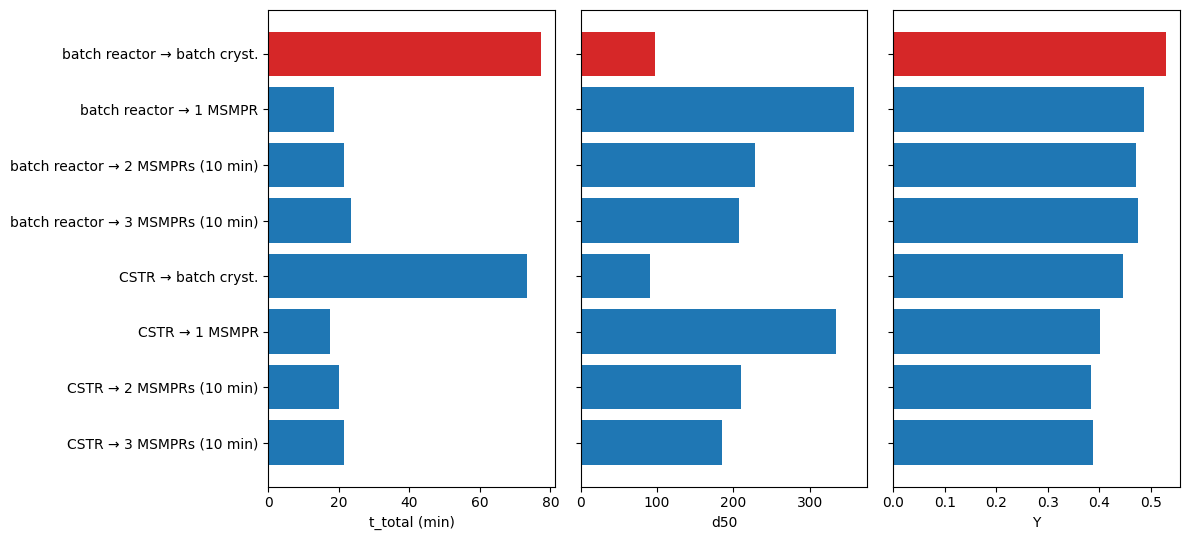

In [11]:
# [blank-start] your code: (d) the same designs with the CSTR product
tic = time.perf_counter()
best_batch_cstr, _ = optimize_batch(FEED_CSTR)
tau_1 = trains.loc[0, 'tau (min)'] * 60
rows = [{'MSMPRs': 1, 'tau (min)': tau_1 / 60, **evaluate(run_msmpr_train(FEED_CSTR, 1, tau_1), tau_1)}]
for n in [2, 3]:
    for tau in [600., 1800.]:
        rows.append({'MSMPRs': n, 'tau (min)': tau / 60, **evaluate(run_msmpr_train(FEED_CSTR, n, tau), tau)})
trains_cstr = pd.DataFrame(rows)
print('time: %.0f s' % (time.perf_counter() - tic))
print('MSMPR trains, CSTR product:')
print(trains_cstr.round(3).to_string())


def train_row(table, n, tau_min=None):
    rows = table[table['MSMPRs'] == n]
    return rows.iloc[0] if tau_min is None else rows[np.isclose(rows['tau (min)'], tau_min)].iloc[0]


cols = ['t_total (min)', 't_cryst (min)', 't_filt (min)', 'd50', 'span', 'Y']
comparison = {}
for feed_label, batch_best, table in [('batch reactor', best_batch, trains), ('CSTR', best_batch_cstr, trains_cstr)]:
    comparison[feed_label + ' → batch cryst.'] = batch_best[cols]
    comparison[feed_label + ' → 1 MSMPR'] = train_row(table, 1)[cols]
    comparison[feed_label + ' → 2 MSMPRs (10 min)'] = train_row(table, 2, 10)[cols]
    comparison[feed_label + ' → 3 MSMPRs (10 min)'] = train_row(table, 3, 10)[cols]
comparison = pd.DataFrame(comparison).T.astype(float)
print(comparison.round(3))
plot_kpi_bars(comparison[['t_total (min)', 'd50', 'Y']])
# [blank-end]

In [12]:
# [blank-start] your code: (e) add the yield specification Y >= 0.50
tic = time.perf_counter()
yield_msmpr = lambda tau: crystal_kpis(run_msmpr_train(FEED_BATCH, 1, tau))['yield']
tau_y = brentq(lambda tau: yield_msmpr(tau) - Y_MIN, 600, 14400, xtol=120)
msmpr_y = evaluate(run_msmpr_train(FEED_BATCH, 1, tau_y), tau_y)
print('time: %.0f s' % (time.perf_counter() - tic))
print('feasible with Y >= %.2f:' % Y_MIN)
print('  best batch (batch-reactor product): t_total = %.0f min, Y = %.3f'
      % (best_batch['t_total (min)'], best_batch['Y']))
print('  1 MSMPR needs tau >= %.0f min: t_total = %.0f min, Y = %.3f'
      % (tau_y / 60, msmpr_y['t_total (min)'], msmpr_y['Y']))
print('  trains of 2-3 MSMPRs: max Y = %.3f' % trains.loc[trains['MSMPRs'] > 1, 'Y'].max())
print('  CSTR product: Y = %.3f (batch crystallizer), max %.3f (any MSMPR train)'
      % (best_batch_cstr['Y'], trains_cstr['Y'].max()))
# [blank-end]

time: 26 s
feasible with Y >= 0.50:
  best batch (batch-reactor product): t_total = 77 min, Y = 0.531
  1 MSMPR needs tau >= 107 min: t_total = 111 min, Y = 0.500
  trains of 2-3 MSMPRs: max Y = 0.481
  CSTR product: Y = 0.447 (batch crystallizer), max 0.401 (any MSMPR train)


---
## Questions to think about

**1.** At the batch optimum of (b), which constraint is active, and what trade-off does it resolve?

<!-- [answer] -->
**Model answer.** With the batch-reactor product, none: the optimum (cooling in about 15 min with $p \approx 0.5$, $t_{total} \approx$ 77 min, $d_{50} \approx$ 98 $\mu m$) is an *interior* optimum. Faster cooling shortens the crystallization but makes smaller crystals that filter more slowly (about 32 min of filtration here vs 21 min after 1 h of cooling); at the optimum one more minute of cooling saves as much filtration time as it costs. With the CSTR product of (d) the size specification becomes active ($d_{50}$ = 90 $\mu m$): the optimizer would cool even faster, but the crystals would get too small.

**2.** Is the best MSMPR train faster than the best batch? What does it give up, and how does the yield specification of (e) change the decision?

<!-- [answer] -->
**Model answer.** Yes, much faster: one MSMPR at its shortest residence time (10 min) needs about 19 min per batch volume against 77 min for the batch, and its large crystals ($d_{50} \approx$ 360 $\mu m$) filter in about 8 min. Its optimum sits on the lower bound of $\tau$, not on the size constraint. It gives up yield (0.49 vs 0.53: the product leaves before the supersaturation is used up) and CSD width (span 1.3 vs 0.7); trains of 2-3 MSMPRs are slower and have even lower yields. With $Y \ge 0.50$ the single MSMPR needs $\tau \ge$ about 107 min ($t_{total} \approx$ 111 min), so the batch wins, and the trains and every design fed with the CSTR product become infeasible. Which route is "best" is decided by the constraints you impose.

**3.** Does the reaction step matter for the crystallization? Why does the CSTR product crystallize differently?

<!-- [answer] -->
**Model answer.** Yes. The CSTR product contains less C (0.92 vs 1.08 mol/L), because a CSTR converts less (0.36 vs 0.20 mol/L of A left) and is less selective. The solubility at `T_C` is the same, so about the same amount of C stays dissolved, and that is a larger share of less C: the crystallization yield drops from 0.53 to 0.45 (batch) and from 0.49 to 0.40 (one MSMPR); the 2- and 3-stage trains lose about as much (0.47-0.48 with the batch-reactor product, 0.38-0.40 with the CSTR product). The lower supersaturation also gives smaller crystals, which makes the size specification active for the batch. Reactor and crystallizer have to be designed together.

**4.** In Part 2, why is the product collected in the holding tank worse than the steady-state product of the MSMPR, and what would you do about it in a plant?

<!-- [answer] -->
**Model answer.** The tank also collects the start-up material. While the CSTR and the MSMPR approach steady state, their product contains less C and crystals formed under different conditions, and the tank keeps crystallizing at `T_C`. The collected product therefore has a lower yield (0.33 vs 0.40) and a broader CSD (span 1.47 vs 1.32) than the steady-state product. In a plant, the start-up material is diverted (or recycled) and collection starts only after a few residence times.

**5.** What is missing from $t_{total}$ before you would choose between batch and continuous?

<!-- [answer] -->
**Model answer.** The cost and size of the equipment (a continuous train of the same volume processes much more material), whether the filter can work in parallel with the next batch (then the cycle time is the longer of $t_{cryst}$ and $t_{filt}$, not their sum), charging, cleaning and start-up times, washing and drying of the cake, and the uncertainty of the kinetics that predict the CSD. The weights between time, yield and size are themselves a business decision.

---
## If you finish early

* Let the batch hold time `T_HOLD` be a third decision variable. What limits how short it can be?
* Seed the batch crystallizer (attach a seeded `OneDFVMMechanism`, as in Challenge 2). Can a seeded batch be as fast as the MSMPR and keep its yield?
* Filter the holding-tank contents of Part 2 at different times: divert the first 2 residence times of product, then collect. How much faster does the collected product filter?
* Dose B in a semibatch reactor (main flowsheet notebook) to raise the selectivity, and see how the better feed changes the batch optimum.